# Оценка взаимной информации: MINE (нижняя граница)

1. Бейзлайны: гистограммный (биннинг) и KSG.
2. MINE: основная валидация - $d=10$, сетка $\rho$ даёт $I$ в диапазоне 2–10 нат, несколько сидов.
3. Тест независимости ($\rho=0$).
4. Инвариантность к биекциям.
5. Абляции: линейный vs MLP-критик, EMA вкл/выкл, сдвиг vs `randperm`, размер батча, ширина сети.


## 0. Импорты

In [ ]:
import math
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.special import digamma

torch.manual_seed(0)
np.random.seed(0)

os.makedirs("figs", exist_ok=True)
SAVE_FIGS = True


def savefig(name):
    if SAVE_FIGS:
        plt.savefig(f"figs/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 1. Вспомогательные функции

In [ ]:
# Гауссовская модель из задания: y = rho*x + sqrt(1-rho^2)*eps.
# Даёт corr(x_i, y_j) = delta_ij * rho, обе маргинали ~ N(0, I).
def sample_gauss(d, rho, n, seed=0):
    rng = np.random.default_rng(seed)

    x = rng.standard_normal((n, d))
    eps = rng.standard_normal((n, d))
    y = rho * x + np.sqrt(1.0 - rho ** 2) * eps
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


# Истинная ВИ (наты): I = -(d/2) * log(1 - rho^2). Только для сравнения.
def true_mi(d, rho):
    return 0.0 - 0.5 * d * np.log(1.0 - rho ** 2)


## 2. Бейзлайны: биннинг и KSG

Оба работают только в малой размерности — поэтому сравниваем их на $d=1$. Служат эталоном «ручного» оценивания ВИ без нейросетей.

In [ ]:
def mi_binning(x, y, bins=10):
    # I = sum_{i,j} p_xy[i,j] * log( p_xy[i,j] / (p_x[i] * p_y[j]) )
    # p_xy — нормированная совместная гистограмма, p_x, p_y — маргиналы.
    x = np.asarray(x).ravel()
    y = np.asarray(y).ravel()

    # равновероятные бины по квантилям, чтобы не было пустых клеток
    ex = np.quantile(x, np.linspace(0.0, 1.0, bins + 1))
    ey = np.quantile(y, np.linspace(0.0, 1.0, bins + 1))

    joint, _ = np.histogramdd(np.stack([x, y], axis=1), bins=[ex, ey])
    joint = joint / joint.sum()          # p(x, y)

    px = joint.sum(axis=1) # p(x)
    py = joint.sum(axis=0) # p(y)

    est = 0.0
    for i in range(bins):
        for j in range(bins):
            if joint[i, j] > 0:
                est += joint[i, j] * np.log(joint[i, j] / (px[i] * py[j]))
    return est


In [ ]:
# Матрица чебышёвских расстояний (max-норма): max_k |a[i,k] - b[j,k]|.
def cheb_dist(a, b):
    return np.max(np.abs(a[:, None, :] - b[None, :, :]), axis=2)


def mi_ksg(x, y, k=5):
    # KSG: I = psi(k) + psi(N) - mean_i[ psi(n_x(i)+1) + psi(n_y(i)+1) ]
    # n_x(i) = #{j: ||x_j - x_i|| < eps_i}, eps_i — расстояние до k-го
    # соседа в СОВМЕСТНОМ пространстве (метрика — max-норма).

    n = x.shape[0]
    xy = np.hstack([x, y])

    d_xy = cheb_dist(xy, xy)
    np.fill_diagonal(d_xy, np.inf) # точка — не свой сосед
    # k-й сосед: partition(kth=k-1) кладёт (k-1)-й наименьший элемент на место k-1

    eps = np.partition(d_xy, k - 1, axis=1)[:, k - 1]

    d_x = cheb_dist(x, x); np.fill_diagonal(d_x, np.inf)
    d_y = cheb_dist(y, y); np.fill_diagonal(d_y, np.inf)
    nx = (d_x < eps[:, None]).sum(axis=1)          # соседи без самой точки
    ny = (d_y < eps[:, None]).sum(axis=1)
    return digamma(k) + digamma(n) - np.mean(digamma(nx + 1) + digamma(ny + 1))


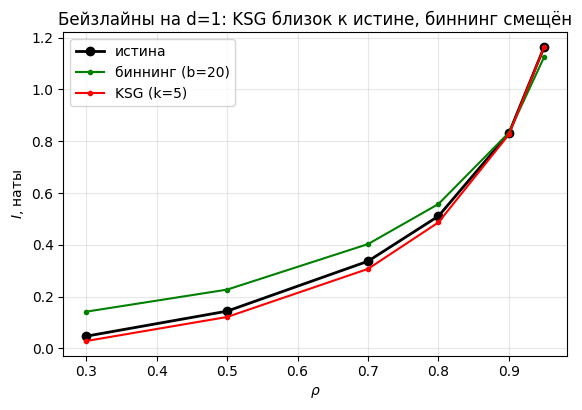

In [ ]:
# Сравнение бейзлайнов на d=1 (биннинг определён только при d=1)
d, n, k = 1, 2000, 5
rhos = np.array([0.3, 0.5, 0.7, 0.8, 0.9, 0.95])

bin_est, ksg_est = [], []
for rho in rhos:
    x, y = sample_gauss(d, rho, n, seed=1)
    x1, y1 = x[:, 0].numpy(), y[:, 0].numpy()
    bin_est.append(mi_binning(x1, y1, bins=20))
    ksg_est.append(mi_ksg(x1[:, None], y1[:, None], k=k))

plt.figure(figsize=(6.5, 4.2))
plt.plot(rhos, true_mi(d, rhos), "k-o", lw=2, label="истина")
plt.plot(rhos, bin_est, "g.-", label="биннинг (b=20)")
plt.plot(rhos, ksg_est, "r.-", label=f"KSG (k={k})")
plt.xlabel(r"$\rho$"); plt.ylabel(r"$I$, наты")
plt.title("Бейзлайны на d=1: KSG близок к истине, биннинг смещён")
plt.legend(); plt.grid(alpha=0.3)
savefig("baselines_d1")


## 3. MINE

Нижняя оценка: $\hat I_{\text{MINE}}=\mathbb{E}_{p(x,y)}[T]-\log\mathbb{E}_{p(x)p(y)}[e^T] \le I$.

- Сеть-критик $T_\theta$ учит $\log\frac{p(x,y)}{p(x)p(y)}$
- оценка — это значение лосса.

In [ ]:
class MLP(nn.Module):
    # Критик T(x, y) -> R. Оптимальный критик в гауссовском случае — квадратичная
    # форма по [x, y], поэтому нужна нелинейность (MLP может её представить).

    def __init__(self, d, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 * d, hidden), nn.ELU(),
            nn.Linear(hidden, hidden), nn.ELU(),
            nn.Linear(hidden, 1),
        )

    def forward(self, x, y):
        return self.net(torch.cat([x, y], dim=1)).squeeze(-1)


class LinearCritic(nn.Module):
    # Абляция: только билинейный член T = w * (x·y). Квадратичные слагаемые
    # ||x||^2, ||y||^2 представить не может, значит оценка систематически занижена.

    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.tensor(1.0))

    def forward(self, x, y):
        return self.w * (x * y).sum(dim=1)


# Отрицательные пары: перемешивание y в батче -> выборка из p(x)p(y).
def negatives(y, mode="randperm"):
    if mode == "randperm":
        return y[torch.randperm(y.shape[0])]
    if mode == "shift":
        return y.roll(1, dims=0)
    raise ValueError(mode)


Оценка $\overline{I}$ - это ещё и лосс, который складывается из двух частей:
1) Скор положительных пар (моделька учится выуживать максимум информации)
2) Минус скор отрицательных пар (та же модель должна не выдавать никакой информации об отрицательных парах, между ними связь нулевая).

Поэтому, когда случайные величины не имеют никакой ВИ, скор нулевой, т.к. перемешанные пары дают тот же скор.

И мы решаем задачу градиентного подъема, поскольку MINE - нижняя оценка на $I$.

In [ ]:
def mine_loss(T, x, y, neg_mode="randperm", use_ema=True, ema_state=None, beta=0.01):
    # I_MINE = E_p[T(x,y)] - log E_{p(x)p(y)}[e^{T(x,y)}]
    # use_ema=True — bias-corrected градиент (из статьи MINE): знаменатель E[e^T]
    # берём из EMA (отвязанная константа), числитель — из текущего батча.

    pos = T(x, y)
    neg = T(x, negatives(y, neg_mode))

    if use_ema:
        me = torch.exp(neg).mean() # E[e^T] по текущему батчу
        if ema_state["me"] is None:
            ema_state["me"] = me.detach()

        # Adam МИНИМИЗИРУЕТ -> лосс = минус оценка
        loss = me / ema_state["me"] - pos.mean()
        est = pos.mean().item() - math.log(ema_state["me"].item())
        ema_state["me"] = (1.0 - beta) * ema_state["me"] + beta * me.detach()

    else:
        second = torch.logsumexp(neg, 0) - math.log(x.shape[0])   # log E[e^T]
        loss = second - pos.mean()
        est = pos.mean().item() - second.item()

    return loss, est

In [ ]:
# Обучает критика и возвращает оценку I на ОТЛОЖЕННЫХ данных.
def train_mine(d, rho, steps=500, bs=512, lr=1e-3, hidden=64, use_ema=True,
               neg_mode="randperm", critic="mlp", seed=0,
               n_train=8192, n_eval=4096, n_eval_batches=8):

    x, y = sample_gauss(d, rho, n_train, seed)
    T = MLP(d, hidden) if critic == "mlp" else LinearCritic()
    opt = torch.optim.Adam(T.parameters(), lr=lr)
    ema_state = {"me": None}

    for _ in range(steps):
        i = torch.randperm(len(x))[:bs]
        loss, _ = mine_loss(T, x[i], y[i], neg_mode, use_ema, ema_state)
        opt.zero_grad()
        loss.backward()
        opt.step()

    # оценка на свежих данных (не на обучающих!)
    xv, yv = sample_gauss(d, rho, n_eval, seed=10_000 + seed)
    ests = []
    with torch.no_grad():
        for _ in range(n_eval_batches):

            i = torch.randperm(len(xv))[:bs]
            pos = T(xv[i], yv[i]).mean().item()

            idx = torch.randperm(len(xv))[:bs]
            neg = T(xv[i], yv[idx])

            second = torch.logsumexp(neg, 0).item() - math.log(len(neg))   # log E[e^T]: len(neg), а не bs (при bs > n_eval расходятся)
            ests.append(pos - second)
    return float(np.mean(ests))


## 4. Основная валидация: d=10, сетка $\rho{} \rightarrow{} 2-10$ нат

Сетка $\rho$ — 30 точек от 0.1 до 0.99 — при $d=10$ даёт $I\approx 0.05\dots19.6$ нат (требуемые 2–10 нат покрываются её частью). MINE обязан лежать **ниже** истины.

In [35]:
D = 10
RHOS = np.linspace(0.1, 0.99, 30)   # I = 0.05 .. 19.6 нат
SEEDS = [0, 1, 2]

print(f"d={D}, {len(RHOS)} точек rho, {len(SEEDS)} сида (MLP-критик, EMA вкл)")
print(f"{'rho':>6} {'I_true':>9} {'I_MINE mean':>13} {'std':>8}")

mine_mean, mine_std = [], []
for rho in RHOS:
    vals = [train_mine(D, rho, seed=s) for s in SEEDS]

    m, sd = float(np.mean(vals)), float(np.std(vals))
    mine_mean.append(m)
    mine_std.append(sd)

    print(f"{rho:6.2f} {true_mi(D, rho):9.3f} {m:13.3f} {sd:8.3f}")


d=10, 30 точек rho, 3 сида (MLP-критик, EMA вкл)
   rho    I_true   I_MINE mean      std
  0.10     0.050         0.041    0.007
  0.13     0.086         0.065    0.007
  0.16     0.132         0.120    0.010
  0.19     0.188         0.176    0.002
  0.22     0.254         0.209    0.013
  0.25     0.332         0.284    0.012
  0.28     0.421         0.394    0.024
  0.31     0.522         0.456    0.017
  0.35     0.636         0.582    0.021
  0.38     0.763         0.717    0.024
  0.41     0.905         0.837    0.054
  0.44     1.063         0.947    0.026
  0.47     1.238         1.158    0.014
  0.50     1.432         1.231    0.106
  0.53     1.646         1.491    0.036
  0.56     1.884         1.653    0.052
  0.59     2.149         1.848    0.030
  0.62     2.443         1.956    0.177
  0.65     2.773         2.048    0.329
  0.68     3.143         2.162    0.501
  0.71     3.562         2.324    0.455
  0.74     4.040         1.719    1.670
  0.78     4.593         3.429 

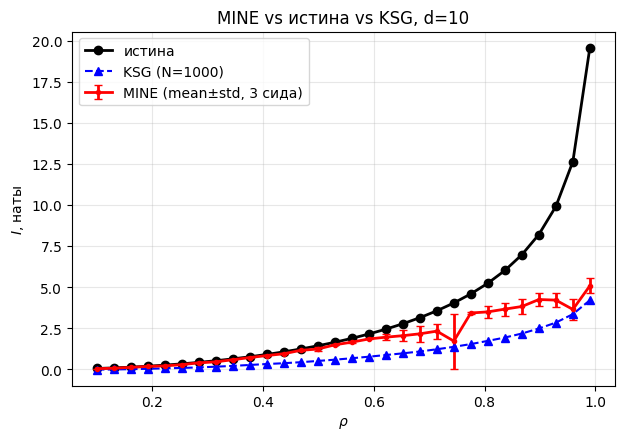

KSG на d=10: [np.float64(-0.018), np.float64(-0.009), np.float64(0.009), np.float64(0.031), np.float64(0.06), np.float64(0.083), np.float64(0.117), np.float64(0.16), np.float64(0.209), np.float64(0.265), np.float64(0.322), np.float64(0.372), np.float64(0.434), np.float64(0.51), np.float64(0.586), np.float64(0.674), np.float64(0.768), np.float64(0.87), np.float64(0.973), np.float64(1.086), np.float64(1.221), np.float64(1.369), np.float64(1.536), np.float64(1.732), np.float64(1.933), np.float64(2.179), np.float64(2.485), np.float64(2.843), np.float64(3.359), np.float64(4.206)]


In [36]:
# KSG как эталон на том же d=10 (N=1000, один сид - kNN на d=10 дорогой и смещён вниз)
ksg_ref = []
for rho in RHOS:
    x, y = sample_gauss(D, rho, 1000, seed=5)
    ksg_ref.append(mi_ksg(x.numpy(), y.numpy(), k=5))

plt.figure(figsize=(7.0, 4.6))
plt.plot(RHOS, true_mi(D, RHOS), "k-o", lw=2, label="истина")
plt.errorbar(RHOS, mine_mean, yerr=mine_std, fmt="r.-", capsize=3, lw=2,
             label=f"MINE (mean±std, {len(SEEDS)} сида)")
plt.plot(RHOS, ksg_ref, "b^--", label="KSG (N=1000)")
plt.xlabel(r"$\rho$"); plt.ylabel(r"$I$, наты")
plt.title(f"MINE vs истина vs KSG, d={D}")
plt.legend()
plt.grid(alpha=0.3)
savefig("mine_main_d10")

print("KSG на d=10:", [round(v, 3) for v in ksg_ref])


## 5. Тест независимости: ρ=0 → оценка ≈ 0

In [ ]:
import time

s_t = time.time()
vals0 = [train_mine(D, 0.0, seed=s) for s in range(100)]
print(f"{time.time() - s_t:2f}с. времени на обучение")

print(f"rho=0, d={D}")
print(f"MINE = {np.mean(vals0):.4f} +- {np.std(vals0):.4f} нат.")

181.064813с. времени на обучение
rho=0, d=10
MINE = -0.0160 +- 0.0051 нат.


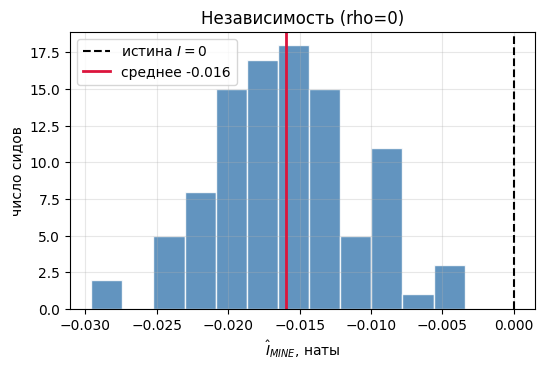

In [ ]:
plt.figure(figsize=(6.0, 3.6))
plt.hist(vals0, bins=12, color="steelblue", alpha=0.85, edgecolor="white")
plt.axvline(0.0, color="k", ls="--", label="истина $I=0$")
plt.axvline(np.mean(vals0), color="crimson", lw=2, label=f"среднее {np.mean(vals0):.3f}")
plt.xlabel(r"$\hat I_{MINE}$, наты"); plt.ylabel("число сидов")
plt.title("Независимость (rho=0)")
plt.legend()
plt.grid(alpha=0.3)

savefig("mine_independence")

## 6. Инвариантность к биекциям

ВИ не меняется при обратимых преобразованиях: $I(X;Y)=I(X;\sinh(Y))$. Корреляция при этом меняется — а хороший оценщик нет.

In [ ]:
# Обучить MINE на данных (xx, yy) и оценить на их отложенной части.
def mine_on_data(xx, yy, d, steps=500, bs=512, seed=0):
    n = len(xx)
    split = int(0.8 * n)
    x_tr, y_tr = xx[:split], yy[:split]
    x_te, y_te = xx[split:], yy[split:]

    T = MLP(d, 64)
    opt = torch.optim.Adam(T.parameters(), lr=1e-3)
    ema = {"me": None}
    for _ in range(steps):
        i = torch.randperm(len(x_tr))[:bs]
        loss, _ = mine_loss(T, x_tr[i], y_tr[i], use_ema=True, ema_state=ema)
        opt.zero_grad(); loss.backward(); opt.step()

    ests = []
    with torch.no_grad():
        for _ in range(8):
            i = torch.randperm(len(x_te))[:bs]
            pos = T(x_te[i], y_te[i]).mean().item()

            idx = torch.randperm(len(x_te))[:bs]
            neg = T(x_te[i], y_te[idx])

            second = torch.logsumexp(neg, 0).item() - math.log(bs)   # log E[e^T]
            ests.append(pos - second)

    return float(np.mean(ests))

In [ ]:
d, rho = 3, 0.8
x, y = sample_gauss(d, rho, 8192, seed=7)

y_sinh = torch.sinh(y)          # нелинейная ОБРАТИМАЯ деформация
A = torch.tensor([[1.5, 0.3, 0.0],   # линейное ОБРАТИМОЕ преобразование (det != 0)
                  [0.1, 1.2, 0.4],
                  [0.0, 0.2, 0.9]])
y_lin = y @ A

i_plain = mine_on_data(x, y, d)
i_sinh = mine_on_data(x, y_sinh, d)
i_lin = mine_on_data(x, y_lin, d)

it = true_mi(d, rho)


def mean_corr(a, b):
    return float(np.mean([np.corrcoef(a[:, j].numpy(), b[:, j].numpy())[0, 1]
                          for j in range(d)]))


print("corr(x,y) =", round(mean_corr(x, y), 3),
      "| corr(x,sinh y) =", round(mean_corr(x, y_sinh), 3),
      "| corr(x,yA) =", round(mean_corr(x, y_lin), 3))

pd.DataFrame(
    {"method": ["Истина", "MINE(x, y)", "MINE(x, sinh(y))", "MINE(x, y·A)"],
     "MI": [it, i_plain, i_sinh, i_lin]}
)


/tmp/ipykernel_1021/2003584317.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.scatter(x_g, np.sinh(y_g), label="sinh(y)", alpha=0.6)


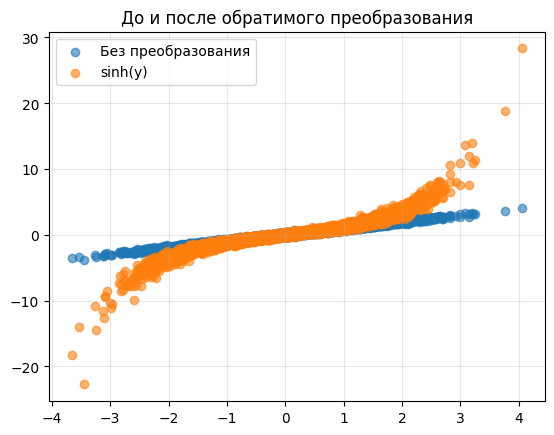

In [ ]:
x_g, y_g = sample_gauss(1, 0.99, 8192, seed=7)

plt.scatter(x_g, y_g, label="Без преобразования", alpha=0.6)
plt.scatter(x_g, np.sinh(y_g), label="sinh(y)", alpha=0.6)

plt.legend()
plt.grid(True, alpha=0.3)
plt.title("До и после обратимого преобразования")

savefig("before_after_transform")

## 7. Абляции

Все при фиксированном $\rho=0.75$, $d=10$ (истина $\approx4.13$ нат). Каждая отключает один компонент метода.
Все значения — среднее по 5 запускам (разным сидам).


In [ ]:
import pandas as pd

# Абляция 1: ёмкость критика — линейный (билинейный) против MLP
# каждое значение — среднее по 5 запускам (разным сидам)
rho = 0.75
it = true_mi(D, rho)
mlp_val = np.mean([train_mine(D, rho, critic="mlp", seed=s) for s in range(5)])
lin_val = np.mean([train_mine(D, rho, critic="linear", seed=s) for s in range(5)])

pd.DataFrame(
    {"method": ["Истина", "MLP", "Линейный"],
     "MI": [it, mlp_val, lin_val]}
)


In [ ]:
# Абляция 2: EMA по отрицательному члену (bias-corrected градиент)
# каждое значение — среднее по 5 запускам (разным сидам)
rho = 0.75
with_ema = np.mean([train_mine(D, rho, use_ema=True, seed=s) for s in range(5)])
without_ema = np.mean([train_mine(D, rho, use_ema=False, seed=s) for s in range(5)])
it = true_mi(D, rho)

pd.DataFrame(
    {"method": ["Истина", "EMA", "NO EMA"],
     "MI": [it, with_ema, without_ema]}
)


In [ ]:
# Абляция 3: способ получения отрицательных пар — сдвиг vs randperm
# каждое значение — среднее по 5 запускам (разным сидам)
rho = 0.75
r_randperm = np.mean([train_mine(D, rho, neg_mode="randperm", seed=s) for s in range(5)])
r_shift = np.mean([train_mine(D, rho, neg_mode="shift", seed=s) for s in range(5)])
it = true_mi(D, rho)

pd.DataFrame(
    {"method": ["Истина", "Перемешивание", "Сдвиг"],
     "MI": [it, r_randperm, r_shift]}
)


In [24]:
# Абляция 4: размер батча (отрицательные пары берутся из батча)
rho = 0.75
bs_list = [(2 ** k) for k in range(1, 12)]
bs_vals = [np.mean([train_mine(D, rho, bs=b, seed=s) for s in range(5)]) for b in bs_list]
it = true_mi(D, rho)

print(f"rho={rho}, истина {it:.3f}")
for b, v in zip(bs_list, bs_vals):
    print(f"  батч {b:5d}: {v:.3f}")

rho=0.75, истина 4.133
  батч     2: 0.607
  батч     4: 1.116
  батч     8: 1.496
  батч    16: 1.584
  батч    32: 1.832
  батч    64: 2.424
  батч   128: 2.465
  батч   256: 2.908
  батч   512: 3.117
  батч  1024: 3.228
  батч  2048: 3.535


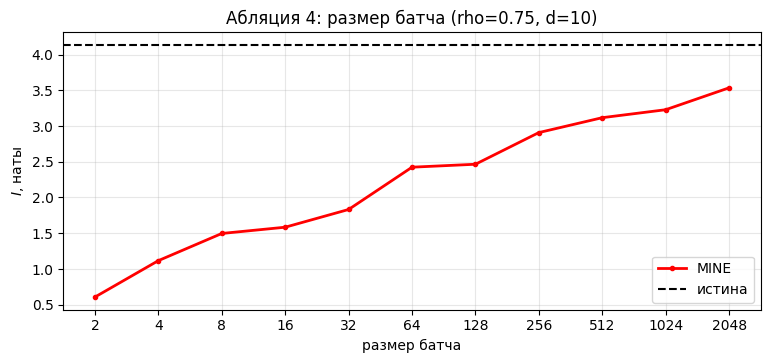

In [25]:
plt.figure(figsize=(9.0, 3.6))
plt.plot(bs_list, bs_vals, "r.-", lw=2, label="MINE")
plt.axhline(it, color="k", ls="--", label="истина")
plt.xscale("log", base=2)
plt.xticks(bs_list, bs_list)
plt.xlabel("размер батча"); plt.ylabel(r"$I$, наты")
plt.title(f"Абляция 4: размер батча (rho={rho}, d={D})")
plt.legend()
plt.grid(alpha=0.3)

savefig("mine_ablation_batch")


In [20]:
# Абляция 5: ширина скрытого слоя (ёмкость)
rho = 0.75
w_list = [(2 ** k) for k in range(2, 9)]
w_vals = [np.mean([train_mine(D, rho, hidden=w, seed=s) for s in range(5)]) for w in w_list]
it = true_mi(D, rho)
print(f"rho={rho}, истина {it:.3f}")
for w, v in zip(w_list, w_vals):
    print(f"  ширина {w:4d}: {v:.3f}")


rho=0.75, истина 4.133
  ширина    4: 0.400
  ширина    8: 1.124
  ширина   16: 2.343
  ширина   32: 2.849
  ширина   64: 3.207
  ширина  128: 3.174
  ширина  256: 3.214


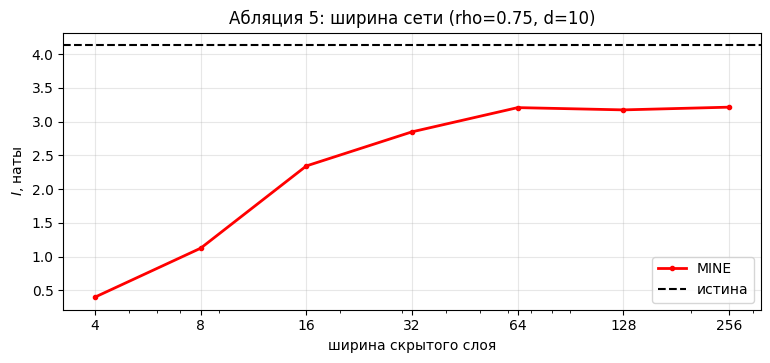

In [21]:
plt.figure(figsize=(9.0, 3.6))
plt.plot(w_list, w_vals, "r.-", lw=2, label="MINE")
plt.axhline(it, color="k", ls="--", label="истина")
plt.xlabel("ширина скрытого слоя")
plt.ylabel(r"$I$, наты")
plt.xscale("log")
plt.xticks(w_list, w_list)

plt.title(f"Абляция 5: ширина сети (rho={rho}, d={D})")
plt.legend()
plt.grid(alpha=0.3)

savefig("mine_ablation_width")

# Знак MINE

<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:6: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_1921/3545790538.py:6: SyntaxWarning: invalid escape sequence '\o'
  plt.plot([0, 10], [0, 10], "k--", lw=1, label="$\overline{I} = I$")


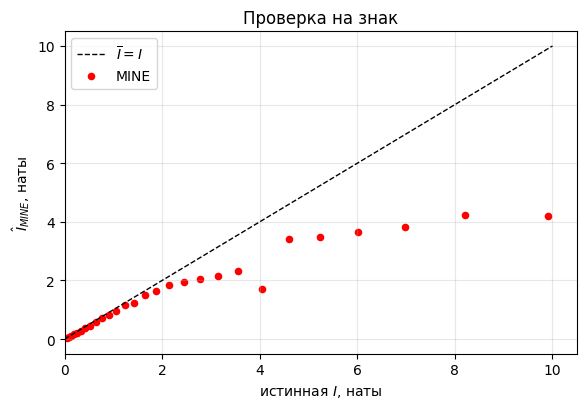

In [53]:
I_true = np.array([float(true_mi(D, r)) for r in RHOS])
I_est  = np.array([float(m) for m in mine_mean])
delta  = I_est - I_true

plt.figure(figsize=(6.0, 4.2))
plt.plot([0, 10], [0, 10], "k--", lw=1, label=r"$\overline{I} = I$")
plt.scatter(I_true, I_est, s=20, color="red", label="MINE")
plt.xlabel("истинная $I$, наты")

plt.ylabel(r"$\hat I_{MINE}$, наты")
plt.title("Проверка на знак")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.xlim(0, float(I_true.max()) + 1)

savefig("mine_sign_graph")

In [50]:
import pandas as pd

table = pd.DataFrame(
    {"rho": RHOS, "I_true": I_true,
    "I_MINE": I_est, "diff": delta}
).round(3)

table.head(7)

,rho,I_true,I_MINE,diff
0,0.100,0.050,0.041,-0.010
1,0.131,0.086,0.065,-0.021
2,0.161,0.132,0.120,-0.012
3,0.192,0.188,0.176,-0.012
4,0.223,0.254,0.209,-0.045
5,0.253,0.332,0.284,-0.048
6,0.284,0.421,0.394,-0.027
